# 05 · Lazzari compositional RNN on emg2pose EMG

**Paper:** Lazzari & Saxena, *Multitasking Recurrent Networks Utilize Compositional Strategies for Control of Movement* (bioRxiv `2025.09.10.675375`).

**Gist:** multitasking RNN + shared manifolds + algebraic/sequential composition for movement control.

**This notebook:** minimal **open-loop** adaptation — discrete leaky RNN maps **sEMG envelopes (+ stage rule)** → **20 joint angles** on the Meta emg2pose mini split. Closed-loop MotorNet, fixed-point/DSA, and composite-rule tests are stubbed.

**Paths:** prefer `Wilbert_EDA/05_*.ipynb` (often gitignored). Tracked copy: `notebooks/experiments/05_lazzari_compositional_rnn/`. Methodology writeup: Project store `docs/paper-methodology-emg-adaptation.md`.

**Assumptions**
- Mini dataset (1 user, 15 stages × 2 hands) is enough for a smoke-test of the *method*, not cross-user claims.
- Stage id ≈ paper "rule" input; continuous recordings lack explicit delay/go epochs.
- Ranking: AE/NMF–PCA remains primary; this is a **latent-state pilot**.


## 0 · Setup (local / cloud — no Colab-only assumptions)


In [1]:
import os, sys, glob, subprocess, math, json
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    p = start.resolve()
    for cand in [p, *p.parents]:
        if (cand / "setup.py").exists() and (cand / "emg2pose").exists():
            return cand
    raise FileNotFoundError("Could not find emg2pose repo root (need setup.py + emg2pose/)")

ROOT = find_repo_root(Path.cwd())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "emg2pose_dataset_mini"
PROCESSED = ROOT / "data" / "processed_mini.npz"
OUT_DIR = ROOT / "data" / "lazzari_emg_pilot"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    url = "https://fb-ctrl-oss.s3.amazonaws.com/emg2pose/emg2pose_dataset_mini.tar"
    tar_path = ROOT / "emg2pose_dataset_mini.tar"
    print("Downloading mini dataset (~617 MB)...")
    subprocess.run(["curl", "-L", "--fail", "-o", str(tar_path), url], check=True)
    subprocess.run(["tar", "-xf", str(tar_path)], check=True)
    tar_path.unlink(missing_ok=True)

print(f"repo: {ROOT}")
print(f"hdf5 files: {len(list(DATA_DIR.glob('*.hdf5')))}")


repo: /agent/repos/emg2pose
hdf5 files: 30


In [2]:
import numpy as np
import h5py
from scipy import signal
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)

FS_IN = 2000
FS_OUT = 50
DECIM = FS_IN // FS_OUT
TRAIN_FRAC = 0.8
GAP = FS_OUT  # 1 s
SEQ_LEN = 100  # 2 s at 50 Hz
HIDDEN = 64
BATCH = 32
EPOCHS = 8
LR = 1e-3
ALPHA_RATE = 1e-4
ALPHA_W = 1e-4
MAX_FILES = None  # set e.g. 8 for a faster smoke test
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)


device: cpu | torch 2.15.0+cpu


## 1 · Load HDF5 → envelopes + joint angles

Paper uses muscle length/velocity feedback from MotorNet. Here **EMG envelopes** are the observed muscle-side signal; **joint angles** are the kinematic targets (20-D instead of planar hand \((x,y)\)).


In [3]:
def envelope_emg(emg: np.ndarray, fs_in=FS_IN, fs_out=FS_OUT) -> np.ndarray:
    """Rectify + low-pass + downsample → (T_out, 16)."""
    x = np.abs(emg.astype(np.float64))
    # 5 Hz Butterworth low-pass on rectified EMG
    b, a = signal.butter(2, 5.0 / (fs_in / 2.0), btype="low")
    x = signal.filtfilt(b, a, x, axis=0)
    # decimate
    n = (len(x) // DECIM) * DECIM
    x = x[:n].reshape(-1, DECIM, x.shape[1]).mean(axis=1)
    return x.astype(np.float32)


def load_recording(path: Path):
    with h5py.File(path, "r") as f:
        ts = f["emg2pose/timeseries"]
        emg = np.asarray(ts["emg"])  # (T, 16)
        pose = np.asarray(ts["joint_angles"])  # (T, 20)
    env = envelope_emg(emg)
    # downsample pose by block mean to match envelopes
    n = (len(pose) // DECIM) * DECIM
    pose = pose[:n].reshape(-1, DECIM, pose.shape[1]).mean(axis=1).astype(np.float32)
    T = min(len(env), len(pose))
    env, pose = env[:T], pose[:T]
    # validity: finite angles
    valid = np.isfinite(pose).all(axis=1)
    name = path.name
    # recording id from filename ...recording-<id>_<side>.hdf5
    rec = name.split("recording-")[1].split("_")[0]
    side = 0.0 if "_left" in name else 1.0
    return {
        "emg": env,
        "pose": pose,
        "valid": valid,
        "stage": rec,
        "side": side,
        "path": str(path),
    }


files = sorted(DATA_DIR.glob("*.hdf5"))
if MAX_FILES is not None:
    files = files[:MAX_FILES]
print(f"loading {len(files)} recordings...")
recs = [load_recording(p) for p in files]
stages = sorted({r["stage"] for r in recs})
stage_to_idx = {s: i for i, s in enumerate(stages)}
N_STAGE = len(stages)
print("stages:", stages)
print("example T:", recs[0]["emg"].shape, "pose", recs[0]["pose"].shape)


loading 30 recordings...


stages: ['1', '10', '11', '12', '13', '14', '15', '2', '3', '4', '5', '6', '7', '8', '9']
example T: (2981, 16) pose (2981, 20)


## 2 · Window dataset with stage one-hot (paper "rule" input)

Each sequence is tagged with a one-hot stage rule, analogous to the paper's task rule vector. Train/test split is **temporal within each recording** (80/20 + 1 s gap), matching notebook 01 practice.


In [4]:
def split_indices(T, train_frac=TRAIN_FRAC, gap=GAP):
    n_train = int(T * train_frac)
    train_end = max(SEQ_LEN, n_train - gap // 2)
    test_start = min(T - SEQ_LEN, n_train + gap // 2)
    return train_end, test_start


def make_windows(rec, split="train"):
    emg, pose, valid = rec["emg"], rec["pose"], rec["valid"]
    T = len(emg)
    train_end, test_start = split_indices(T)
    if split == "train":
        starts = range(0, train_end - SEQ_LEN + 1, SEQ_LEN // 2)
    else:
        starts = range(test_start, T - SEQ_LEN + 1, SEQ_LEN // 2)
    rule = np.zeros(N_STAGE, dtype=np.float32)
    rule[stage_to_idx[rec["stage"]]] = 1.0
    side = np.array([rec["side"]], dtype=np.float32)
    out = []
    for s in starts:
        sl = slice(s, s + SEQ_LEN)
        if valid[sl].mean() < 0.9:
            continue
        x = np.concatenate([emg[sl], np.tile(rule, (SEQ_LEN, 1)), np.tile(side, (SEQ_LEN, 1))], axis=1)
        y = pose[sl]
        out.append((x.astype(np.float32), y.astype(np.float32)))
    return out


class SeqDataset(Dataset):
    def __init__(self, pairs):
        self.x = [torch.from_numpy(x) for x, _ in pairs]
        self.y = [torch.from_numpy(y) for _, y in pairs]

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


train_pairs, test_pairs = [], []
for r in recs:
    train_pairs.extend(make_windows(r, "train"))
    test_pairs.extend(make_windows(r, "test"))

# standardize EMG channels using train windows only
emg_dim = 16
all_train_emg = np.concatenate([x[:, :emg_dim] for x, _ in train_pairs], axis=0)
emg_mean = all_train_emg.mean(0)
emg_std = all_train_emg.std(0) + 1e-6
pose_all = np.concatenate([y for _, y in train_pairs], axis=0)
pose_mean = pose_all.mean(0)
# poses left in radians as-is; report MAE in degrees later


def standardize_pairs(pairs):
    out = []
    for x, y in pairs:
        x = x.copy()
        x[:, :emg_dim] = (x[:, :emg_dim] - emg_mean) / emg_std
        out.append((x, y))
    return out

train_pairs = standardize_pairs(train_pairs)
test_pairs = standardize_pairs(test_pairs)
print(f"windows train={len(train_pairs)} test={len(test_pairs)} | input_dim={train_pairs[0][0].shape[1]}")

train_loader = DataLoader(SeqDataset(train_pairs), batch_size=BATCH, shuffle=True, drop_last=True)
test_loader = DataLoader(SeqDataset(test_pairs), batch_size=BATCH, shuffle=False)


windows train=1632 test=364 | input_dim=32


## 3 · Discrete leaky RNN (paper §4.1, open-loop decode)

Paper: RNN → sigmoid muscle stim → MotorNet → hand position.  
**Here:** RNN → linear readout → joint angles. Same discretized leaky integrator; no plant.


In [5]:
class LeakyRNN(nn.Module):
    """Paper-style discretized continuous-time rate RNN."""

    def __init__(self, n_in, n_hidden, n_out, tau=5.0, dt=1.0, act="softplus"):
        super().__init__()
        self.alpha = dt / tau
        self.W_h = nn.Parameter(0.1 * torch.randn(n_hidden, n_hidden) / math.sqrt(n_hidden))
        self.W_in = nn.Linear(n_in, n_hidden, bias=True)
        self.readout = nn.Linear(n_hidden, n_out, bias=True)
        if act == "softplus":
            self.act = nn.Softplus()
        elif act == "tanh":
            self.act = nn.Tanh()
        else:
            self.act = nn.ReLU()

    def forward(self, u, return_hidden=False):
        # u: (B, T, N_in)
        B, T, _ = u.shape
        h = u.new_zeros(B, self.W_h.shape[0])
        x = u.new_zeros(B, self.W_h.shape[0])
        outs, hs = [], []
        for t in range(T):
            # x_t = (1-a) x_{t-1} + a (W_h h + W_in u + b)
            pre = h @ self.W_h.T + self.W_in(u[:, t])
            x = (1.0 - self.alpha) * x + self.alpha * pre
            h = self.act(x)
            outs.append(self.readout(h))
            if return_hidden:
                hs.append(h)
        yhat = torch.stack(outs, dim=1)
        if return_hidden:
            return yhat, torch.stack(hs, dim=1)
        return yhat


n_in = train_pairs[0][0].shape[1]
model = LeakyRNN(n_in, HIDDEN, 20, tau=5.0, dt=1.0, act="softplus").to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR)
print(model)
print("params:", sum(p.numel() for p in model.parameters()))


LeakyRNN(
  (W_in): Linear(in_features=32, out_features=64, bias=True)
  (readout): Linear(in_features=64, out_features=20, bias=True)
  (act): Softplus(beta=1.0, threshold=20.0)
)
params: 7508


## 4 · Train with adapted paper losses

Kept: trajectory/pose MSE (\(L_1\)), \(\ell_1\) on rates (\(L_2\)), \(\ell_1\) on \(W_h\) (\(L_3\)).  
Dropped / stubbed: muscle \(\ell_1\) (\(L_4\)), dynamics loss (\(L_5\)) — need MotorNet / Jacobian tooling.


In [6]:
def batch_loss(yhat, y, h=None, wh=None):
    mse = torch.mean((yhat - y) ** 2)
    rate_pen = torch.tensor(0.0, device=y.device)
    if h is not None:
        rate_pen = torch.mean(torch.abs(h))
    if wh is None:
        wh = model.W_h
    w_pen = torch.mean(torch.abs(wh))
    return mse + ALPHA_RATE * rate_pen + ALPHA_W * w_pen, mse.item(), rate_pen.item(), w_pen.item()


def mae_deg(yhat, y):
    return (yhat - y).abs().mean().item() * (180.0 / math.pi)


history = {"train_mse": [], "test_mae_deg": [], "baseline_mae_deg": []}

# mean-pose baseline from training targets
pose_mean_t = torch.from_numpy(pose_mean.astype(np.float32)).to(DEVICE)


@torch.no_grad()
def evaluate():
    model.eval()
    maes, base = [], []
    for xb, yb in test_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        yhat = model(xb)
        maes.append(mae_deg(yhat, yb))
        base.append(mae_deg(pose_mean_t.expand_as(yb), yb))
    return float(np.mean(maes)), float(np.mean(base))


for epoch in range(1, EPOCHS + 1):
    model.train()
    mse_run = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        yhat, h = model(xb, return_hidden=True)
        loss, mse_v, _, _ = batch_loss(yhat, yb, h, model.W_h)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        mse_run.append(mse_v)
    test_mae, base_mae = evaluate()
    history["train_mse"].append(float(np.mean(mse_run)))
    history["test_mae_deg"].append(test_mae)
    history["baseline_mae_deg"].append(base_mae)
    print(f"epoch {epoch:02d} | train MSE {history['train_mse'][-1]:.5f} | test MAE {test_mae:.2f}° | mean-pose {base_mae:.2f}°")

ckpt = OUT_DIR / "leaky_rnn_mini.pt"
torch.save({"model": model.state_dict(), "history": history, "stage_to_idx": stage_to_idx,
            "emg_mean": emg_mean, "emg_std": emg_std, "n_in": n_in, "hidden": HIDDEN}, ckpt)
print("saved", ckpt)


epoch 01 | train MSE 0.19284 | test MAE 17.01° | mean-pose 17.36°


epoch 02 | train MSE 0.16294 | test MAE 16.57° | mean-pose 17.36°


epoch 03 | train MSE 0.15149 | test MAE 16.00° | mean-pose 17.36°


epoch 04 | train MSE 0.14099 | test MAE 15.71° | mean-pose 17.36°


epoch 05 | train MSE 0.12983 | test MAE 15.53° | mean-pose 17.36°


epoch 06 | train MSE 0.12578 | test MAE 15.42° | mean-pose 17.36°


epoch 07 | train MSE 0.12387 | test MAE 15.33° | mean-pose 17.36°


epoch 08 | train MSE 0.12118 | test MAE 15.29° | mean-pose 17.36°
saved /agent/repos/emg2pose/data/lazzari_emg_pilot/leaky_rnn_mini.pt


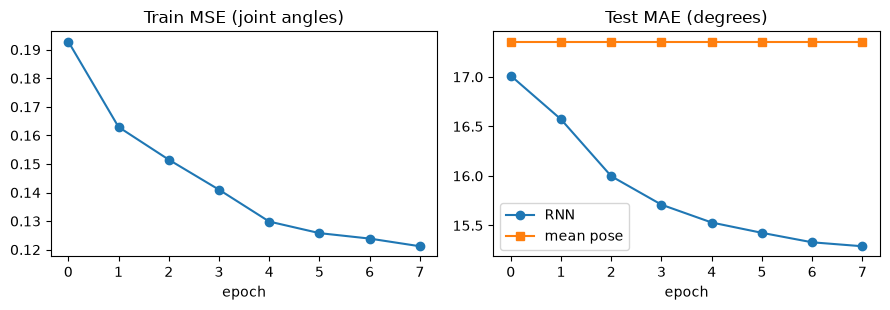

final test MAE °: 15.289374757387742 | baseline: 17.356507604030007


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(history["train_mse"], marker="o")
ax[0].set_title("Train MSE (joint angles)")
ax[0].set_xlabel("epoch")
ax[1].plot(history["test_mae_deg"], marker="o", label="RNN")
ax[1].plot(history["baseline_mae_deg"], marker="s", label="mean pose")
ax[1].set_title("Test MAE (degrees)")
ax[1].set_xlabel("epoch")
ax[1].legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "train_curves.png", dpi=120)
plt.show()
print("final test MAE °:", history["test_mae_deg"][-1], "| baseline:", history["baseline_mae_deg"][-1])


## 5 · Shared-manifold check (paper §4.3, simplified)

Collect hidden trajectories per stage; compare principal angles between stage subspaces vs random bases. This is the first compositional / shared-manifold probe without MotorNet.


mean principal angle (top modes) across stage pairs: 0.312 rad
random-bases mean: 1.154 rad
(smaller than random → more shared subspace structure)


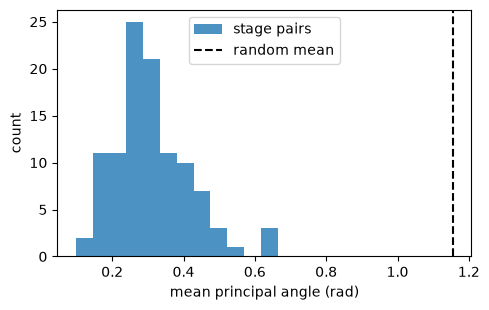

In [8]:
@torch.no_grad()
def collect_hidden_by_stage(max_per_stage=40):
    model.eval()
    buckets = {s: [] for s in stages}
    # rebuild a few standardized full windows labeled by stage
    for r in recs:
        pairs = standardize_pairs(make_windows(r, "test"))
        if not pairs:
            pairs = standardize_pairs(make_windows(r, "train"))
        for x, _ in pairs[:max_per_stage]:
            xb = torch.from_numpy(x).unsqueeze(0).to(DEVICE)
            _, h = model(xb, return_hidden=True)
            buckets[r["stage"]].append(h.squeeze(0).cpu().numpy())
    return {s: np.concatenate(v, axis=0) for s, v in buckets.items() if v}


def pca_basis(X, var=0.95, max_k=12):
    X = X - X.mean(0, keepdims=True)
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    expl = (S ** 2) / (S ** 2).sum()
    k = int(np.searchsorted(np.cumsum(expl), var) + 1)
    k = max(2, min(k, max_k, Vt.shape[0]))
    return Vt[:k].T  # (N, k)


def principal_angles(A, B):
    # A,B orthonormal bases (N,k)
    qa, _ = np.linalg.qr(A)
    qb, _ = np.linalg.qr(B)
    _, s, _ = np.linalg.svd(qa.T @ qb)
    s = np.clip(s, 0, 1)
    return np.arccos(s)


hid = collect_hidden_by_stage()
bases = {s: pca_basis(X) for s, X in hid.items()}
stage_list = [s for s in stages if s in bases]
angles = []
for i, s1 in enumerate(stage_list):
    for s2 in stage_list[i + 1 :]:
        ang = principal_angles(bases[s1], bases[s2])
        angles.append(ang[: min(3, len(ang))].mean())

# random baseline
rng = np.random.default_rng(0)
rand_angs = []
N = HIDDEN
for _ in range(200):
    k = 6
    A, _ = np.linalg.qr(rng.normal(size=(N, k)))
    B, _ = np.linalg.qr(rng.normal(size=(N, k)))
    rand_angs.append(principal_angles(A, B)[:3].mean())

print(f"mean principal angle (top modes) across stage pairs: {np.mean(angles):.3f} rad")
print(f"random-bases mean: {np.mean(rand_angs):.3f} rad")
print("(smaller than random → more shared subspace structure)")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(angles, bins=12, alpha=0.8, label="stage pairs")
ax.axvline(np.mean(rand_angs), color="k", ls="--", label="random mean")
ax.set_xlabel("mean principal angle (rad)")
ax.set_ylabel("count")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "principal_angles.png", dpi=120)
plt.show()


## 6 · Stubs (paper analyses not run in v0)

Mark these explicitly so the next iteration can fill them without redesigning I/O.

### 6.1 MotorNet closed loop — STUB
Paper trains RNN ↔ musculoskeletal arm with proprio/visual feedback. emg2pose gives **measured** EMG and pose; there is no stim→muscle plant in-repo.  
**Next:** either (a) keep open-loop decoding, or (b) optional teacher-forced delayed pose feedback as a poor man's loop.

### 6.2 Composite rule inputs (§4.5) — STUB
Optimize \(\zeta \odot u_{	ext{rule}}\) from other stages' one-hots to match a held-out stage's pose while freezing \(W_h\).

### 6.3 Sequencing / mid-trial rule switch (§4.6) — STUB
Needs clearer motif boundaries than continuous stage HDF5s provide; try hand-crafted stage pairs after Motif labeling.

### 6.4 Fixed points + DSA (§4.7–4.8) — STUB
After a stronger model: optimize \(h^*\) with fixed input; HAVOK/DMD similarity across stages.

### 6.5 Transfer learning (§4.9) — partial sketch below
Freeze recurrent weights; fit only input columns / readout on a held-out stage.


In [9]:
# --- Transfer sketch: freeze Wh / recurrent path; adapt W_in + readout on one held-out stage ---
HOLD_OUT = stages[-1]
print("held-out stage for transfer sketch:", HOLD_OUT)

# rebuild loaders excluding / including holdout
pre_train, pre_test, ft_train, ft_test = [], [], [], []
for r in recs:
    tr = standardize_pairs(make_windows(r, "train"))
    te = standardize_pairs(make_windows(r, "test"))
    if r["stage"] == HOLD_OUT:
        ft_train.extend(tr); ft_test.extend(te)
    else:
        pre_train.extend(tr); pre_test.extend(te)

print(f"pretrain windows={len(pre_train)} | finetune={len(ft_train)} test_holdout={len(ft_test)}")

transfer_model = LeakyRNN(n_in, HIDDEN, 20, tau=5.0, dt=1.0, act="softplus").to(DEVICE)
transfer_model.load_state_dict(model.state_dict())  # warm start from multitask model

# freeze recurrent matrix
transfer_model.W_h.requires_grad_(False)

# brief finetune of input + readout only
opt_ft = torch.optim.Adam([p for p in transfer_model.parameters() if p.requires_grad], lr=LR)
ft_loader = DataLoader(SeqDataset(ft_train), batch_size=min(BATCH, max(1, len(ft_train))), shuffle=True)
hold_loader = DataLoader(SeqDataset(ft_test if ft_test else ft_train), batch_size=min(BATCH, max(1, len(ft_test) or len(ft_train))), shuffle=False)

@torch.no_grad()
def mae_loader(m, loader):
    m.eval(); vals=[]
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        vals.append(mae_deg(m(xb), yb))
    return float(np.mean(vals)) if vals else float("nan")

before = mae_loader(transfer_model, hold_loader)
for step in range(30):
    transfer_model.train()
    for xb, yb in ft_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt_ft.zero_grad()
        yhat, h = transfer_model(xb, return_hidden=True)
        loss, _, _, _ = batch_loss(yhat, yb, h, transfer_model.W_h.detach())
        loss.backward()
        opt_ft.step()
after = mae_loader(transfer_model, hold_loader)
print(f"holdout MAE before FT: {before:.2f}° → after input/readout FT: {after:.2f}°")
print("Note: this is a sketch on mini (same user); real test is held-out *users* on full data.")


held-out stage for transfer sketch: 9
pretrain windows=1538 | finetune=94 test_holdout=20


holdout MAE before FT: 15.70° → after input/readout FT: 12.91°
Note: this is a sketch on mini (same user); real test is held-out *users* on full data.


## 7 · Assumptions, blockers, next steps

**Assumptions**
- Stage labels from filenames are meaningful "tasks" for compositionality probes.
- Softplus leaky RNN is a faithful enough stand-in for the paper's rate model.
- Open-loop EMG→pose is a valid first port; closed-loop control is out of scope for v0.

**What ran vs stubbed**
| Piece | Status |
|-------|--------|
| Mini HDF5 load + envelopes | runs |
| Multitask leaky RNN train/eval | runs |
| Mean-pose baseline | runs |
| Principal-angle shared manifold | runs |
| Input/readout transfer sketch | runs (light) |
| MotorNet / \(L_4\)/\(L_5\) | stub |
| Composite rules / sequencing / FP / DSA | stub |

**Next experiments**
1. Longer training + all windows with notebook-01 `processed_mini.npz` cache.
2. NMF synergies → RNN → PCA eigenpostures (tie to Aim 1 / Santi pipeline).
3. Proper calibration curves (freeze \(W_h\); vary # finetune minutes).
4. Full-dataset held-out users before claiming compositionality benefits.

**Wilbert: where to get this file**
- Preferred local: `Wilbert_EDA/05_lazzari_compositional_rnn_emg.ipynb` (often gitignored on his machine).
- Pull via PR / tracked path: `notebooks/experiments/05_lazzari_compositional_rnn/05_lazzari_compositional_rnn_emg.ipynb`.
- Project Context download: `docs/05_lazzari_compositional_rnn_emg.ipynb` + `docs/paper-methodology-emg-adaptation.md`.
